In [118]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator


In [119]:
load_dotenv()

True

In [120]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [121]:
# For structured output, we will define a schema inheriting the BaseModel
class EvaluationSchema(BaseModel):
    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10') #ge = Greater than equal to, le = Less than equal to

In [122]:
structured_model = model.with_structured_output(EvaluationSchema)


In [123]:
essay = """How AI Is Impacting the World Economy

Artificial Intelligence (AI) has become one of the most important technologies in the modern world. It is changing the way people live, work, communicate, and do business. AI is also playing a major role in shaping the global economy by improving productivity, creating new opportunities, and transforming different industries.

One of the biggest advantages of AI is that it helps businesses save time and reduce costs. Companies use AI to automate repetitive tasks, analyse large amounts of data, and make better decisions. Industries such as healthcare, education, banking, manufacturing, and transportation are using AI to improve their services and efficiency. For example, AI helps doctors identify diseases, supports students in learning, and helps businesses understand customer needs.

AI is also creating new job opportunities in areas such as software development, data science, robotics, and cybersecurity. Many countries are investing in AI technology to strengthen their economies and remain competitive in the global market. As a result, AI is becoming an important factor in economic growth and innovation.

However, AI also has some disadvantages. Automation may replace certain traditional jobs, which could lead to unemployment in some sectors. Small businesses may also find it difficult to compete with large companies that have access to advanced AI technology. In addition, issues such as data privacy, cybersecurity, and the responsible use of AI need proper attention.

In conclusion, Artificial Intelligence is transforming the world economy in both positive and negative ways. Although it brings certain challenges, its benefits can be significant if it is used responsibly. Governments, businesses, and individuals should work together to adapt to these changes and ensure that AI creates a better and more sustainable future for everyone."""

essay1 = """# How AI Is Impacting the World Economy

AI is one of the most important thing in the world today. It have changed many things in our daily life and also effecting the world economy. Many people think AI is very useful but some people are not happy with it.

Nowadays many company are using AI for doing there work. It help them to save time and money. AI can do many works faster than humans and it also make less mistakes. In future AI will be used in every field and people will depend on it more.

AI is also creating some problem for peoples. Many workers are losing there jobs because AI can do there work easily. For example, in offices many task are now done by computers. This is making people worried about there future. Also AI sometimes give wrong information and people trust it without checking.

Another problem is that many countries are spending lot of money on AI but poor countries cannot afford this technology. So the gap between rich and poor countries can become more bigger.

In my opinion AI is good as well as bad for the world economy. It have many benefits but it also have disadvantages. People should use AI carefully and not depend on it completely. Government should also make some rules for using AI so that everyone can get benefit from it.

At last, AI is the future of the world and it will changes our life in many ways."""

In [124]:
#  


In [125]:
class UPSCState(TypedDict):
    essay:str
    language_feeback : str
    analysis_feedback : str
    clarity_feedback : str
    overall_feedback : str
    individual_score : Annotated[list[int], operator.add]
    avg_score : int

In [126]:
def evaluate_language(state:UPSCState):
    prompt = f"Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {'language_feeback' : output.feedback, 'individual_score' : [output.score]}

In [127]:
def evaluate_analysis(state:UPSCState):
    prompt = f"Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {'analysis_feedback' : output.feedback, 'individual_score' : [output.score]}

In [128]:
def evaluate_thought(state:UPSCState):
    prompt = f"Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}"
    output = structured_model.invoke(prompt)
    return {'clarity_feedback' : output.feedback, 'individual_score' : [output.score]}

In [129]:
def final_evaluation(state:UPSCState):
    prompt = f"Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feeback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state['clarity_feedback']}"
    overall_feedback = model.invoke(prompt).content
    average = sum(state["individual_score"])/len(state["individual_score"])
    return {'overall_feedback' : overall_feedback, 'avg_score' : average}

 

In [130]:
graph = StateGraph(UPSCState)
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('final_evaluation', final_evaluation)


In [131]:
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_thought')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge('evaluate_language' , 'final_evaluation')
graph.add_edge('evaluate_thought' , 'final_evaluation')
graph.add_edge('evaluate_analysis' , 'final_evaluation')
graph.add_edge('final_evaluation', END)

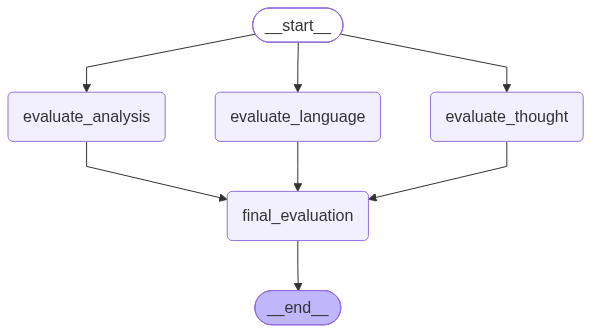

In [132]:
workflow = graph.compile()
workflow

In [133]:
initial_state = {
    'essay' : essay1
}
workflow.invoke(initial_state)

{'essay': '# How AI Is Impacting the World Economy\n\nAI is one of the most important thing in the world today. It have changed many things in our daily life and also effecting the world economy. Many people think AI is very useful but some people are not happy with it.\n\nNowadays many company are using AI for doing there work. It help them to save time and money. AI can do many works faster than humans and it also make less mistakes. In future AI will be used in every field and people will depend on it more.\n\nAI is also creating some problem for peoples. Many workers are losing there jobs because AI can do there work easily. For example, in offices many task are now done by computers. This is making people worried about there future. Also AI sometimes give wrong information and people trust it without checking.\n\nAnother problem is that many countries are spending lot of money on AI but poor countries cannot afford this technology. So the gap between rich and poor countries can be